<a href="https://colab.research.google.com/github/Ashwini9713/fundamentals-of-ML/blob/main/exp_13.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Shape: (1500, 8)
    Brand  Year  Kms_Driven Fuel_Type Transmission  Owner  Engine_CC  \
0  Toyota  2011       94678    Petrol       Manual      1       2000   
1     BMW  2011      117056    Diesel       Manual      2        800   
2   Honda  2024       59238       CNG       Manual      2       1200   
3     BMW  2019       63608    Diesel       Manual      1       2000   
4     BMW  2024       94081    Diesel       Manual      2       1200   

   Price_Lakhs  
0     8.033064  
1    13.320332  
2     9.262844  
3    20.538182  
4    19.531977   

Linear Regression  R2: 0.973 | MAE: 0.621 | RMSE: 0.792
Random Forest      R2: 0.940 | MAE: 0.935 | RMSE: 1.173


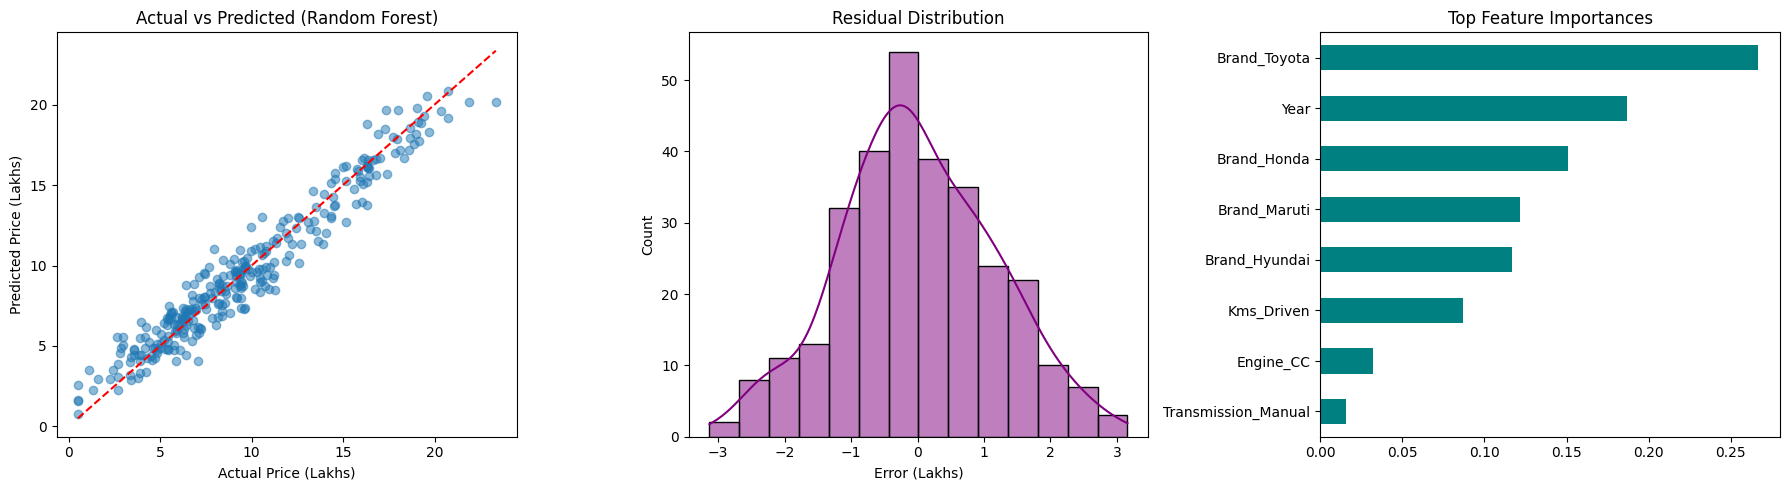


Predicted Price: 11.04 Lakhs


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

# 1. Create dataset (replace with pd.read_csv("car_data.csv") for a real dataset)
np.random.seed(42)
n = 1500
df = pd.DataFrame({
    "Brand": np.random.choice(["Maruti", "Hyundai", "Honda", "Toyota", "BMW"], n),
    "Year": np.random.randint(2008, 2025, n),
    "Kms_Driven": np.random.randint(5000, 150000, n),
    "Fuel_Type": np.random.choice(["Petrol", "Diesel", "CNG"], n),
    "Transmission": np.random.choice(["Manual", "Automatic"], n),
    "Owner": np.random.randint(1, 4, n),
    "Engine_CC": np.random.choice([800, 1000, 1200, 1500, 2000], n),
})
brand_value = {"Maruti": 3, "Hyundai": 4, "Honda": 5, "Toyota": 6, "BMW": 14}
price = (df["Brand"].map(brand_value)
         + 0.4 * (df["Year"] - 2008)
         - 0.00003 * df["Kms_Driven"]
         + 0.002 * df["Engine_CC"]
         + 1.5 * (df["Transmission"] == "Automatic")
         + 0.8 * (df["Fuel_Type"] == "Diesel")
         - 0.7 * df["Owner"]
         + np.random.normal(0, 0.8, n))
df["Price_Lakhs"] = price.clip(0.5)

print("Shape:", df.shape)
print(df.head(), "\n")

# 2. Preprocessing: one-hot encode categorical columns
X = pd.get_dummies(df.drop("Price_Lakhs", axis=1), drop_first=True)
y = df["Price_Lakhs"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Train models
lr = LinearRegression().fit(X_train, y_train)
rf = RandomForestRegressor(n_estimators=200, random_state=42).fit(X_train, y_train)

# 4. Evaluate
def evaluate(name, model):
    p = model.predict(X_test)
    print(f"{name:<18} R2: {r2_score(y_test, p):.3f} | MAE: {mean_absolute_error(y_test, p):.3f} | RMSE: {np.sqrt(mean_squared_error(y_test, p)):.3f}")
    return p
lr_pred = evaluate("Linear Regression", lr)
rf_pred = evaluate("Random Forest", rf)

# 5. Graphs
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
ax[0].scatter(y_test, rf_pred, alpha=0.5)
ax[0].plot([y.min(), y.max()], [y.min(), y.max()], "r--")
ax[0].set_title("Actual vs Predicted (Random Forest)")
ax[0].set_xlabel("Actual Price (Lakhs)"); ax[0].set_ylabel("Predicted Price (Lakhs)")

sns.histplot(y_test - rf_pred, kde=True, ax=ax[1], color="purple")
ax[1].set_title("Residual Distribution"); ax[1].set_xlabel("Error (Lakhs)")

pd.Series(rf.feature_importances_, index=X.columns).sort_values().tail(8).plot(kind="barh", ax=ax[2], color="teal")
ax[2].set_title("Top Feature Importances")
plt.tight_layout()
plt.show()

# 6. Predict a new car
new = pd.DataFrame([{"Brand": "Honda", "Year": 2019, "Kms_Driven": 40000, "Fuel_Type": "Petrol",
                     "Transmission": "Manual", "Owner": 1, "Engine_CC": 1200}])
new = pd.get_dummies(new).reindex(columns=X.columns, fill_value=0)
print(f"\nPredicted Price: {rf.predict(new)[0]:.2f} Lakhs")